# Երևանի ճանապարհային ցանցի ուսումնասիրություն՝ գրաֆների տեսության և խցանումների մոդելավորման միջոցով

## Նպատակ և մեթոդաբանություն
Աշխատանքի հիմնական միտքը պահպանված է՝ Երևանի Կենտրոնի ճանապարհային ցանցը ներկայացնել ուղղորդված կշռված գրաֆի տեսքով, A կետից B կետ գտնել ամենակարճ և ամենաարագ երթուղիները և պատկերել արդյունքները քարտեզի վրա։

**Տվյալների պարզաբանում․** ճանապարհային ցանցի աշխարհագրական կառուցվածքը ներբեռնվում է OpenStreetMap-ից։ Խցանումները իրական ժամանակի չափումներ չեն․ դրանք սինթետիկ են և օգտագործվում են մոդելավորման համար։ Արդյունքները չեն ներկայացնում տվյալ պահի իրական երթևեկությունը։


## 1. Գրադարանների տեղադրում

In [ ]:
%pip -q install osmnx networkx folium pandas matplotlib numpy

## 2. Գրադարանների ներմուծում և կրկնելի արդյունքներ

In [ ]:
import random, math, warnings, hashlib
import osmnx as ox
import networkx as nx
import numpy as np
import pandas as pd
import folium
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print("OSMnx:", ox.__version__, "| NetworkX:", nx.__version__)

OSMnx: 2.1.1 | NetworkX: 3.7


## 3. Ճանապարհային ցանցի ներբեռնում
Ուսումնասիրության տարածքը Երևանի Կենտրոն վարչական շրջանն է։ Գագաթները ներկայացնում են ճանապարհային հանգույցները, իսկ կողերը՝ ճանապարհային հատվածները։ Գրաֆն ուղղորդված է, քանի որ ճանապարհների մի մասը միակողմանի է։

In [ ]:
place_name = "Kentron, Yerevan, Armenia"
G = ox.graph_from_place(place_name, network_type="drive", simplify=True)

if G.number_of_nodes() == 0 or G.number_of_edges() == 0:
    raise RuntimeError("Ճանապարհային ցանցը չի ներբեռնվել։ Ստուգեք ինտերնետային կապը կամ տեղանքի անվանումը։")

print("Գագաթներ:", G.number_of_nodes())
print("Կողեր:", G.number_of_edges())
print("Ուղղորդված գրաֆ:", G.is_directed())

Գագաթներ: 863
Կողեր: 1747
Ուղղորդված գրաֆ: True


## 4. Գրաֆի կառուցվածքային վերլուծություն

,Ցուցանիշ,Արժեք
0,Գագաթների քանակ,863.000
1,Կողերի քանակ,1747.000
2,Միջին ընդհանուր աստիճան,4.049
3,Առավելագույն ընդհանուր աստիճան,10.000
4,Թույլ կապակցված բաղադրիչներ,1.000
5,Ուժեղ կապակցված բաղադրիչներ,20.000
6,Ամենամեծ թույլ բաղադրիչի գագաթներ,863.000


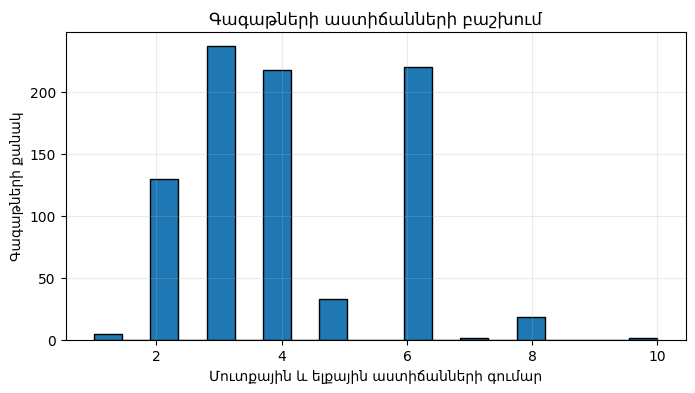

In [ ]:
in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
degrees = [in_deg[n] + out_deg[n] for n in G.nodes()]
weak = list(nx.weakly_connected_components(G))
strong = list(nx.strongly_connected_components(G))

summary = pd.DataFrame({
    "Ցուցանիշ": ["Գագաթների քանակ", "Կողերի քանակ", "Միջին ընդհանուր աստիճան",
                 "Առավելագույն ընդհանուր աստիճան", "Թույլ կապակցված բաղադրիչներ",
                 "Ուժեղ կապակցված բաղադրիչներ", "Ամենամեծ թույլ բաղադրիչի գագաթներ"],
    "Արժեք": [G.number_of_nodes(), G.number_of_edges(), round(np.mean(degrees), 3),
              max(degrees), len(weak), len(strong), len(max(weak, key=len))]
})
display(summary)

plt.figure(figsize=(8,4))
plt.hist(degrees, bins=20, edgecolor="black")
plt.title("Գագաթների աստիճանների բաշխում")
plt.xlabel("Մուտքային և ելքային աստիճանների գումար")
plt.ylabel("Գագաթների քանակ")
plt.grid(alpha=.25)
plt.show()

## 5. Խցանումների սինթետիկ մոդելավորում

Խցանումների սցենարը հիմնվում է Կենտրոնում հանդիպող ճանապարհների դասերի և հրապարակային դիտարկումներում հիշատակվող փողոցների վրա։ Հիմնական և միջին նշանակության ճանապարհների համար ծանրաբեռնվածության հավանականությունն ավելի բարձր է, քան տեղական փողոցների համար։

Յուրաքանչյուր ֆիզիկական հատվածի վիճակը որոշվում է մեկ անգամ և կիրառվում է երկու ուղղությունների նկատմամբ, երբ դրանք առկա են։ Ֆիքսված պատահական սերմի շնորհիվ արդյունքները վերարտադրելի են։ Փակ հատվածները սինթետիկ սցենար են, ոչ թե իրական վթարի հաստատված տվյալներ։

In [ ]:
BASE_SPEED_MPS = 40 * 1000 / 3600

heavy_streets = [
    "մյասնիկյան", "myasnikyan", "հերացու", "heratsi", "խանջյան", "khanjyan",
    "սարալանջ", "saralanj", "արշակունյաց", "arshakunyats",
    "ագաթանգեղոս", "agatangeghos", "մաշտոց", "mashtots",
    "տիգրան մեծ", "tigran mets", "իսակով", "isakov"
]
medium_streets = [
    "բաղրամյան", "baghramyan", "աբովյան", "abovyan", "տերյան", "teryan",
    "կորյուն", "koryun", "սայաթ-նովա", "sayat-nova", "ամիրյան", "amiryan",
    "թումանյան", "tumanyan", "գրիգոր լուսավորիչ", "grigor lusavorich",
    "նալբանդյան", "nalbandyan", "չարենց", "charents", "կոմիտաս", "komitas",
    "օրբելի", "orbeli", "կիևյան", "kievyan"
]

def norm_name(value):
    if isinstance(value, list):
        return " ".join(map(str, value)).lower()
    return str(value or "").lower()

def segment_rng(u, v, road_name):
    endpoints = sorted((str(u), str(v)))
    raw = f"{RANDOM_SEED}|{endpoints[0]}|{endpoints[1]}|{road_name}".encode("utf-8")
    seed = int(hashlib.sha256(raw).hexdigest()[:16], 16)
    return random.Random(seed)

segment_state = {}
for u, v, k, d in G.edges(keys=True, data=True):
    d["length"] = max(float(d.get("length", 1)), 1.0)
    d["base_time"] = d["length"] / BASE_SPEED_MPS
    name_str = " ".join([
        norm_name(d.get("name")),
        norm_name(d.get("name:hy")),
        norm_name(d.get("name:en"))
    ])
    highway = d.get("highway", "")
    if isinstance(highway, list):
        highway = highway[0] if highway else ""
    highway = str(highway)
    road_name = name_str.strip() or highway
    segment_key = (tuple(sorted((str(u), str(v)))), road_name)

    if segment_key not in segment_state:
        rng = segment_rng(u, v, road_name)
        r = rng.random()
        is_heavy = any(s in name_str for s in heavy_streets)
        is_medium = any(s in name_str for s in medium_streets)

        if r < 0.004:
            state = (math.inf, "closed")
        elif is_heavy or highway in ("trunk", "primary"):
            state = ((3.0, "severe") if r < 0.42 else
                     (2.5, "heavy") if r < 0.78 else
                     (1.5, "light") if r < 0.94 else (1.0, "free"))
        elif is_medium or highway == "secondary":
            state = ((3.0, "severe") if r < 0.16 else
                     (2.5, "heavy") if r < 0.43 else
                     (1.5, "light") if r < 0.78 else (1.0, "free"))
        elif highway == "tertiary":
            state = ((3.0, "severe") if r < 0.06 else
                     (2.5, "heavy") if r < 0.24 else
                     (1.5, "light") if r < 0.58 else (1.0, "free"))
        else:
            state = ((2.5, "heavy") if r < 0.025 else
                     (1.5, "light") if r < 0.16 else (1.0, "free"))
        segment_state[segment_key] = state

    mult, status = segment_state[segment_key]
    d["congestion_multiplier"] = mult
    d["traffic_status"] = status
    d["congested"] = mult > 1.0 and math.isfinite(mult)
    d["traffic_time"] = d["base_time"] * mult

status_labels = {
    "free": "Ազատ (կանաչ, ×1.0)",
    "light": "Թույլ խցանում (դեղին, ×1.5)",
    "heavy": "Ուժեղ խցանում (կարմիր, ×2.5)",
    "severe": "Շատ ուժեղ խցանում (մուգ կարմիր, ×3.0)",
    "closed": "Սցենարային փակ հատված"
}
status_counts = pd.Series([
    status_labels[d["traffic_status"]]
    for _, _, _, d in G.edges(keys=True, data=True)
]).value_counts()
factor_counts = pd.Series([
    d["congestion_multiplier"]
    for _, _, _, d in G.edges(keys=True, data=True)
    if d["congested"] and math.isfinite(d["congestion_multiplier"])
]).value_counts().sort_index()

print("Մոդելավորված խցանված կամ փակ հատվածներ:",
      sum(1 for _, _, _, d in G.edges(keys=True, data=True)
          if d["traffic_status"] == "closed" or d["congested"]))
display(status_counts.rename_axis("Վիճակ").to_frame("Հատվածների քանակ"))

Մոդելավորված խցանված կամ փակ հատվածներ: 868


,Հատվածների քանակ
Վիճակ,
"Ազատ (կանաչ, ×1.0)",879
"Թույլ խցանում (դեղին, ×1.5)",341
"Ուժեղ խցանում (կարմիր, ×2.5)",293
"Շատ ուժեղ խցանում (մուգ կարմիր, ×3.0)",229
Սցենարային փակ հատված,5


## 6. Խցանումների վիճակագրություն

Խցանված հատվածներ՝ 863 / 1747
Սցենարային փակ հատվածներ՝ 5
Միջին դանդաղեցման գործակից՝ 2.24
Խցանված հատվածների երկարություն՝ 119.63 կմ


,length_m,multiplier,base_time_s,traffic_time_s
count,863.00,863.00,863.00,863.00
mean,138.62,2.24,12.48,28.55
std,170.81,0.63,15.37,37.86
min,1.70,1.50,0.15,0.23
25%,30.32,1.50,2.73,5.66
50%,97.18,2.50,8.75,17.94
75%,183.15,3.00,16.48,34.48
max,1828.99,3.00,164.61,401.14


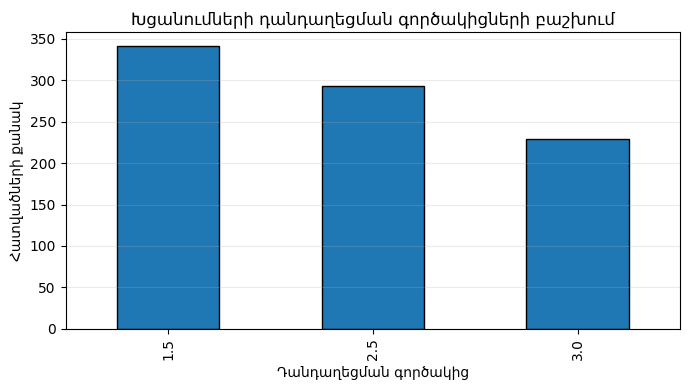

In [ ]:
edge_rows = []
for u, v, k, d in G.edges(keys=True, data=True):
    edge_rows.append({
        "u": u, "v": v, "key": k, "length_m": d["length"],
        "multiplier": d["congestion_multiplier"],
        "congested": d["congested"], "status": d["traffic_status"],
        "base_time_s": d["base_time"], "traffic_time_s": d["traffic_time"]
    })

edges_df = pd.DataFrame(edge_rows)
congested_df = edges_df[edges_df["congested"] & np.isfinite(edges_df["multiplier"])]
closed_df = edges_df[edges_df["status"] == "closed"]

print(f"Խցանված հատվածներ՝ {len(congested_df)} / {len(edges_df)}")
print(f"Սցենարային փակ հատվածներ՝ {len(closed_df)}")
if not congested_df.empty:
    print(f"Միջին դանդաղեցման գործակից՝ {congested_df['multiplier'].mean():.2f}")
    print(f"Խցանված հատվածների երկարություն՝ {congested_df['length_m'].sum()/1000:.2f} կմ")
    display(congested_df[["length_m", "multiplier", "base_time_s", "traffic_time_s"]].describe().round(2))
else:
    print("Խցանված հատվածներ չեն ընտրվել։")

plt.figure(figsize=(7, 4))
if not factor_counts.empty:
    factor_counts.plot(kind="bar", edgecolor="black")
else:
    plt.text(0.5, 0.5, "Խցանված հատվածներ չկան", ha="center", va="center")
plt.title("Խցանումների դանդաղեցման գործակիցների բաշխում")
plt.xlabel("Դանդաղեցման գործակից")
plt.ylabel("Հատվածների քանակ")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Միջնորդական կենտրոնականություն

Միջնորդական կենտրոնականությունը գնահատում է, թե որքան հաճախ է գագաթը գտնվում այլ գագաթների կարճագույն ճանապարհների վրա։ Հաշվարկն արվում է ճանապարհի երկարությամբ՝ ուղղորդված գրաֆի վրա։ Մեծ արժեքները կարող են ցույց տալ ցանցի կարևոր հանգույցներ։ Հաշվարկը մոտավոր է՝ մինչև 200 գագաթի նմուշով։

In [ ]:
k_sample = min(200, G.number_of_nodes())
bc = nx.betweenness_centrality(
    G, k=k_sample if k_sample < G.number_of_nodes() else None,
    weight="length", normalized=True, seed=RANDOM_SEED
)
top_nodes = sorted(bc.items(), key=lambda x:x[1], reverse=True)[:10]
centrality_df = pd.DataFrame([
    {"Գագաթ":n, "Կենտրոնականություն":val,
     "Լայնություն":G.nodes[n]["y"], "Երկայնություն":G.nodes[n]["x"]}
    for n,val in top_nodes
])
display(centrality_df.round(6))

,Գագաթ,Կենտրոնականություն,Լայնություն,Երկայնություն
0,10830785385,0.130993,40.174123,44.500752
1,632031882,0.130087,40.178584,44.515120
2,4688983926,0.127602,40.178147,44.512302
3,4209742296,0.126912,40.174861,44.505487
4,354684596,0.126463,40.178136,44.512202
5,3830401745,0.120679,40.181005,44.507684
6,4685816051,0.115679,40.174217,44.500613
7,4758463192,0.114541,40.175636,44.498741
8,256037322,0.113693,40.174808,44.505362
9,354684572,0.107150,40.177799,44.512005


## 8. A և B կետերի ընտրություն
Ընտրվում են իրարից տարածականորեն տարբեր և ուղղորդված ճանապարհով հասանելի երկու գագաթ։

In [ ]:
# Երթուղու որոնման համար ժամանակավորապես փակ հատվածները հեռացնում ենք։
G_open = nx.MultiDiGraph()
G_open.graph.update(G.graph)
G_open.add_nodes_from(G.nodes(data=True))
G_open.add_edges_from(
    (u, v, k, d.copy())
    for u, v, k, d in G.edges(keys=True, data=True)
    if math.isfinite(d["traffic_time"])
)
if G_open.number_of_edges() == 0:
    raise RuntimeError("Բաց ճանապարհային հատվածներ չեն մնացել։")

# Ընտրում ենք ամենամեծ ուժեղ կապակցված բաղադրիչից A և B,
# որպեսզի երթուղու հասանելիությունը երաշխավորված լինի։
scc_nodes = max(nx.strongly_connected_components(G_open), key=len)
candidate_nodes = list(scc_nodes)
if len(candidate_nodes) < 2:
    raise RuntimeError("Բավարար չափի ուժեղ կապակցված բաղադրիչ չի գտնվել։")

pair_rng = random.Random(RANDOM_SEED + 101)
source_node = target_node = None
for _ in range(5000):
    a, b = pair_rng.sample(candidate_nodes, 2)
    delta = abs(G.nodes[a]["y"] - G.nodes[b]["y"]) + abs(G.nodes[a]["x"] - G.nodes[b]["x"])
    if delta > 0.015:
        source_node, target_node = a, b
        break
if source_node is None:
    source_node, target_node = pair_rng.sample(candidate_nodes, 2)

print("Ուժեղ կապակցված բաղադրիչի գագաթներ:", len(candidate_nodes))
print("A:", source_node, (G.nodes[source_node]["y"], G.nodes[source_node]["x"]))
print("B:", target_node, (G.nodes[target_node]["y"], G.nodes[target_node]["x"]))

Ուժեղ կապակցված բաղադրիչի գագաթներ: 833
A: 11644940327 (40.183693, 44.523483)
B: 6277544437 (40.1691139, 44.5154033)


## 9. Երթուղիների որոնում՝ Դեյկստրա և A*
Համեմատվում են ամենակարճ երթուղին՝ ըստ մետրերով երկարության, և ամենաարագ երթուղին՝ ըստ սինթետիկ խցանումները հաշվի առնող ժամանակի։ A* ալգորիթմի հեվրիստիկան ուղիղ հեռավորությունն է՝ բաժանված բազային արագության վրա։ Քանի որ դանդաղեցման գործակիցները 1-ից փոքր չեն, այս հեվրիստիկան չի գերագնահատում ճանապարհի մնացած ժամանակը։

In [ ]:
def min_parallel_weight(u, v, edge_data, weight_name):
    values = [
        float(data.get(weight_name, math.inf))
        for data in edge_data.values()
        if math.isfinite(float(data.get(weight_name, math.inf)))
    ]
    return min(values) if values else math.inf

def haversine_m(a, b):
    lat1, lon1 = math.radians(G.nodes[a]["y"]), math.radians(G.nodes[a]["x"])
    lat2, lon2 = math.radians(G.nodes[b]["y"]), math.radians(G.nodes[b]["x"])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    h = math.sin(dlat / 2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon / 2)**2
    return 2 * 6371000 * math.asin(math.sqrt(h))

def heuristic(node, target):
    # Ուղիղ հեռավորություն / առավելագույն բազային արագություն՝ ադմիսիբլ հեվրիստիկա։
    return haversine_m(node, target) / BASE_SPEED_MPS

weight_time = lambda u, v, data: min_parallel_weight(u, v, data, "traffic_time")
weight_length = lambda u, v, data: min_parallel_weight(u, v, data, "length")

path_fast_dijkstra = nx.shortest_path(
    G_open, source_node, target_node, weight=weight_time, method="dijkstra"
)
path_fast_astar = nx.astar_path(
    G_open, source_node, target_node, heuristic=heuristic, weight=weight_time
)
path_shortest = nx.shortest_path(
    G_open, source_node, target_node, weight=weight_length, method="dijkstra"
)
print("Դեյկստրա և A* երթուղիները համընկնում են՝", path_fast_dijkstra == path_fast_astar)
print("Ամենաարագ երթուղու գագաթներ՝", len(path_fast_dijkstra))
print("Ամենակարճ երթուղու գագաթներ՝", len(path_shortest))

Դեյկստրա և A* երթուղիները համընկնում են՝ True
Ամենաարագ երթուղու գագաթներ՝ 20
Ամենակարճ երթուղու գագաթներ՝ 21


## 10. Երթուղիների երկարության և ժամանակի հաշվարկ

In [ ]:
def best_edge(u, v, weight_name):
    parallel = G_open[u][v]
    valid = [
        (key, data) for key, data in parallel.items()
        if math.isfinite(float(data.get(weight_name, math.inf)))
    ]
    if not valid:
        raise ValueError(f"{u} → {v} անցման համար բաց կող չի գտնվել։")
    return min(valid, key=lambda item: float(item[1][weight_name]))[1]

def route_metrics(path, objective="traffic_time"):
    length, seconds, congestion_count = 0.0, 0.0, 0
    for u, v in zip(path[:-1], path[1:]):
        # Ընտրում ենք զուգահեռ կողը նույն չափանիշով, որով գտնվել է երթուղին։
        edge = best_edge(u, v, "length" if objective == "length" else "traffic_time")
        length += float(edge["length"])
        seconds += float(edge["traffic_time"])
        congestion_count += int(bool(edge["congested"]))
    return {
        "Երկարություն (կմ)": length / 1000,
        "Մոդելավորված ժամանակ (րոպե)": seconds / 60,
        "Խցանված հատվածներ": congestion_count,
        "Գագաթների քանակ": len(path)
    }

routes = {
    "Ամենակարճ՝ ըստ հեռավորության": (path_shortest, "length"),
    "Ամենաարագ՝ Դեյկստրա": (path_fast_dijkstra, "traffic_time"),
    "Ամենաարագ՝ A*": (path_fast_astar, "traffic_time")
}
results = pd.DataFrame({
    name: route_metrics(path, objective)
    for name, (path, objective) in routes.items()
}).T
display(results.round(2))

,Երկարություն (կմ),Մոդելավորված ժամանակ (րոպե),Խցանված հատվածներ,Գագաթների քանակ
Ամենակարճ՝ ըստ հեռավորության,2.29,8.58,13.0,21.0
Ամենաարագ՝ Դեյկստրա,2.86,6.12,7.0,20.0
Ամենաարագ՝ A*,2.86,6.12,7.0,20.0


## 11. Խցանումների ազդեցության համեմատություն
Հաշվարկվում է ամենաարագ երթուղին նաև առանց խցանումների։ Համեմատությունը ցույց է տալիս՝ ինչպես են սինթետիկ դանդաղեցումները փոխում ընտրված երթուղին և մոդելավորված ժամանակը։

In [ ]:
# Նույն A-B զույգի ամենաարագ երթուղին՝ առանց խցանումների։
for u, v, k, d in G_open.edges(keys=True, data=True):
    d["free_time"] = float(d["base_time"])

weight_free = lambda u, v, data: min_parallel_weight(u, v, data, "free_time")
path_free = nx.shortest_path(
    G_open, source_node, target_node, weight=weight_free, method="dijkstra"
)

def path_time(path, field):
    return sum(
        float(best_edge(u, v, field)[field])
        for u, v in zip(path[:-1], path[1:])
    )

free_minutes = path_time(path_free, "free_time") / 60
congested_minutes = path_time(path_fast_dijkstra, "traffic_time") / 60
time_change = congested_minutes - free_minutes
time_change_pct = (time_change / free_minutes * 100) if free_minutes > 0 else 0

impact = pd.DataFrame({
    "Ցուցանիշ": [
        "Առանց խցանումների՝ ամենաարագ երթուղի",
        "Խցանումներով՝ ամենաարագ երթուղի",
        "Ժամանակի փոփոխություն",
        "Ժամանակի փոփոխություն (%)"
    ],
    "Արժեք": [
        f"{free_minutes:.2f} րոպե",
        f"{congested_minutes:.2f} րոպե",
        f"{time_change:+.2f} րոպե",
        f"{time_change_pct:+.1f}%"
    ]
})
display(impact)
print("Խցանումների պատճառով երթուղին փոխվել է՝", path_free != path_fast_dijkstra)

,Ցուցանիշ,Արժեք
0,Առանց խցանումների՝ ամենաարագ երթուղի,3.44 րոպե
1,Խցանումներով՝ ամենաարագ երթուղի,6.12 րոպե
2,Ժամանակի փոփոխություն,+2.67 րոպե
3,Ժամանակի փոփոխություն (%),+77.7%


Խցանումների պատճառով երթուղին փոխվել է՝ True


## 12. Google Maps քարտեզի վրա խցանումների և երթուղիների ցուցադրում

Քարտեզի ֆոնը Google Maps է՝ նույն tile շերտով, որն օգտագործված էր սկզբնական notebook-ում։ Գրաֆի եզրերը, խցանումների գույները, A/B կետերը և երթուղիների հաշվարկը պահպանված են։

## 12. Քարտեզի վիզուալիզացիա
Գույները ցույց են տալիս սինթետիկ խցանումների ուժգնությունը։ Կանաչը ցույց է տալիս ամենակարճ, իսկ մանուշակագույնը՝ խցանումները հաշվի առնող ամենաարագ երթուղին։

In [ ]:
center = [
    np.mean([G.nodes[n]["y"] for n in G.nodes()]),
    np.mean([G.nodes[n]["x"] for n in G.nodes()])
]
google_tiles = "https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}"
traffic_map = folium.Map(
    location=center, zoom_start=14, tiles=google_tiles,
    attr="Google Maps", control_scale=True
)

def edge_color(mult):
    if not math.isfinite(mult): return "#808080"
    if mult >= 3.0: return "#8B0000"
    if mult >= 2.5: return "#E31A1C"
    if mult >= 1.5: return "#FFD700"
    return "#2E8B57"

def edge_points(u, v, data):
    if "geometry" in data:
        xs, ys = data["geometry"].xy
        return list(zip(ys, xs))
    return [(G.nodes[u]["y"], G.nodes[u]["x"]),
            (G.nodes[v]["y"], G.nodes[v]["x"])]

for u, v, key, data in G.edges(keys=True, data=True):
    tooltip = (
        f"{data.get('name', 'Անանուն ճանապարհ')} | "
        f"Վիճակ՝ {status_labels[data['traffic_status']]} | "
        f"Երկարություն՝ {data['length']:.0f} մ"
    )
    folium.PolyLine(
        edge_points(u, v, data),
        color=edge_color(data["congestion_multiplier"]),
        weight=3.0 if data["congested"] else (2.2 if data["traffic_status"] == "closed" else 1.5),
        opacity=0.9 if data["congested"] or data["traffic_status"] == "closed" else 0.65,
        tooltip=tooltip
    ).add_to(traffic_map)

def draw_route(path, color, label, width, objective):
    for u, v in zip(path[:-1], path[1:]):
        edge = best_edge(u, v, objective)
        folium.PolyLine(
            edge_points(u, v, edge),
            color=color, weight=width, opacity=0.98, tooltip=label
        ).add_to(traffic_map)

draw_route(path_shortest, "#0066CC", "Ամենակարճ երթուղի", 5, "length")
draw_route(path_fast_dijkstra, "#7B2CBF", "Ամենաարագ երթուղի՝ Դեյկստրա", 6, "traffic_time")

folium.Marker(
    [G.nodes[source_node]["y"], G.nodes[source_node]["x"]],
    tooltip="A — Մեկնարկ", icon=folium.Icon(color="green", icon="play")
).add_to(traffic_map)
folium.Marker(
    [G.nodes[target_node]["y"], G.nodes[target_node]["x"]],
    tooltip="B — Նպատակակետ", icon=folium.Icon(color="red", icon="flag")
).add_to(traffic_map)

legend_html = '''
<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;
padding:10px;border:1px solid #777;border-radius:6px;font-size:12px;line-height:1.6">
<b>Խցանումների մոդել</b><br>
<span style="color:#2E8B57">━</span> Ազատ ճանապարհ (×1.0)<br>
<span style="color:#FFD700">━</span> Թույլ խցանում (×1.5)<br>
<span style="color:#E31A1C">━</span> Ուժեղ խցանում (×2.5)<br>
<span style="color:#8B0000">━</span> Շատ ուժեղ խցանում (×3.0)<br>
<span style="color:#808080">━</span> Սցենարային փակ հատված<br>
<span style="color:#0066CC">━</span> Ամենակարճ երթուղի<br>
<span style="color:#7B2CBF">━</span> Ամենաարագ երթուղի
<hr style="margin:4px 0">
<small>Սինթետիկ մոդել, ոչ իրական ժամանակի երթևեկություն</small>
</div>
'''
traffic_map.get_root().html.add_child(folium.Element(legend_html))
display(traffic_map)

## 13. Երթուղիների համեմատական գրաֆիկներ

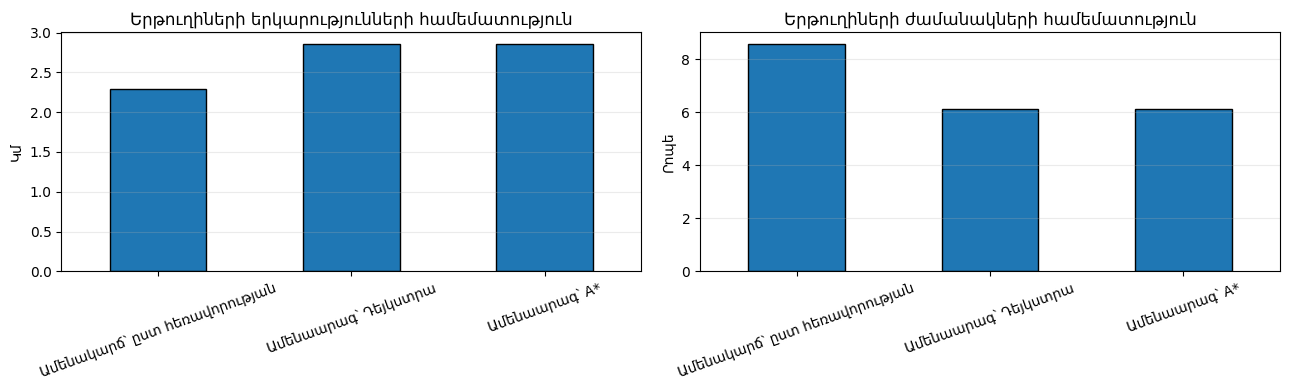

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
results["Երկարություն (կմ)"].plot(kind="bar",ax=axes[0],edgecolor="black")
axes[0].set_title("Երթուղիների երկարությունների համեմատություն")
axes[0].set_ylabel("Կմ")
axes[0].tick_params(axis="x",rotation=20)
axes[0].grid(axis="y",alpha=.25)
results["Մոդելավորված ժամանակ (րոպե)"].plot(kind="bar",ax=axes[1],edgecolor="black")
axes[1].set_title("Երթուղիների ժամանակների համեմատություն")
axes[1].set_ylabel("Րոպե")
axes[1].tick_params(axis="x",rotation=20)
axes[1].grid(axis="y",alpha=.25)
plt.tight_layout()
plt.show()

## 14. Եզրակացություն և արդյունքների մեկնաբանություն

 Ճանապարհային ցանցը ներկայացվել է ուղղորդված կշռված գրաֆի տեսքով։ Ճանապարհների երկարությունները կիրառվել են որպես հեռավորության կշիռներ, իսկ անցման ժամանակը՝ որպես խցանումներով փոփոխվող կշիռ։ Դեյկստրայի և A* ալգորիթմներով գտնվել են երթուղիներ նույն ժամանակային չափանիշով։ Առանց խցանումների և խցանումներով երթուղիների համեմատությունը գնահատում է սինթետիկ ծանրաբեռնվածության ազդեցությունը։


## 15. Սահմանափակումներ և հետագա զարգացում

- Ցանցը ներառում է Կենտրոն վարչական շրջանը, ոչ թե ամբողջ Երևանը։
- Խցանումները սինթետիկ են և չեն ներկայացնում իրական ժամանակի չափված արագություններ։
- Բազային արագությունը հաստատուն է՝ 40 կմ/ժ, իսկ դանդաղեցման գործակիցները մոդելային ենթադրություններ են։
- Սցենարային փակ հատվածները չեն նշանակում, որ այդ ճանապարհներն իրականում փակ են կամ վթար է տեղի ունեցել։
- Չեն մոդելավորվում լուսացույցները, մեքենաների իրական հոսքը, եղանակը, վարորդների վարքագիծը և խաչմերուկների սպասման ժամանակը։
- Google Maps-ը notebook-ում օգտագործվում է որպես քարտեզային ֆոն, ոչ թե որպես երթևեկության տվյալների աղբյուր։
- Հետագայում մոդելը կարելի է բարելավել իրական երթևեկության API-ի օրինական հասանելի տվյալներով, ժամային տարբեր սցենարներով և չափված ճանապարհային արագություններով։
